# Bonus 1 & 2 — Détection d'anomalies et sélection de caractéristiques

1. **Clients atypiques** : Isolation Forest (population complète) et bruit DBSCAN (échantillon) ; comparaison et profilage.
2. **Sélection de caractéristiques avant clustering** : filtre de variance, filtre de corrélation, méthode *wrapper* (sélection pas à pas), et une variante « profil client pur » sans indicateurs macro-économiques.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score, v_measure_score
from sklearn.preprocessing import MinMaxScaler

from src.config import SEED, DATA_PROC, FIGURES, RESULTS
from src.preprocessing import load_processed, load_raw, NUM_FEATURES, BIN_FEATURES, CAT_FEATURES

sns.set_theme(style="whitegrid", palette="tab10"); plt.rcParams["figure.dpi"] = 110
def save(fig, name): fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

d = load_processed()
X, idx, y, clean = d["X_a"], d["sample_idx"], d["y"].to_numpy(), d["clean"]
raw = load_raw().drop_duplicates().reset_index(drop=True)
labels_final = np.load(DATA_PROC / "labels_final.npy")
feat_names = list(joblib.load("../models/preprocessing_pipeline.joblib").get_feature_names_out())

## Partie A — Détection d'anomalies
### A.1 Isolation Forest
Principe : un point atypique est **isolé en peu de coupures aléatoires** ; le score d'anomalie est lié à la profondeur moyenne d'isolement dans une forêt d'arbres aléatoires. On fixe une contamination de 1 %.

Clients atypiques : 411 (1.0 %)


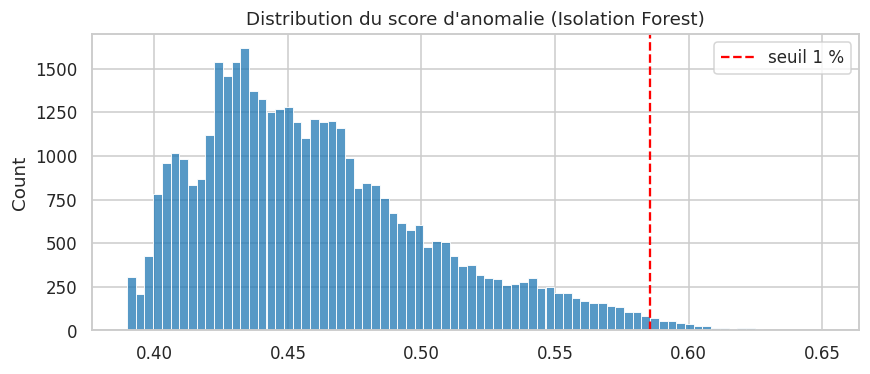

In [2]:
iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=SEED, n_jobs=-1).fit(X)
score = -iso.score_samples(X)                       # plus grand = plus atypique
is_anom = iso.predict(X) == -1
print(f"Clients atypiques : {is_anom.sum()} ({100*is_anom.mean():.1f} %)")
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(score, bins=80, ax=ax); ax.axvline(score[is_anom].min(), color="red", ls="--", label="seuil 1 %")
ax.set_title("Distribution du score d'anomalie (Isolation Forest)"); ax.legend(); save(fig, "b1_iforest_scores")

In [3]:
comp = pd.DataFrame({
    "atypiques": [clean.loc[is_anom, "age"].mean(), raw.loc[is_anom, "campaign"].mean(),
                  clean.loc[is_anom, "previous"].mean(), 100 * (clean.loc[is_anom, "poutcome"] == "success").mean(),
                  100 * clean.loc[is_anom, "job"].isin(["retired", "student"]).mean(), 100 * y[is_anom].mean()],
    "autres": [clean.loc[~is_anom, "age"].mean(), raw.loc[~is_anom, "campaign"].mean(),
               clean.loc[~is_anom, "previous"].mean(), 100 * (clean.loc[~is_anom, "poutcome"] == "success").mean(),
               100 * clean.loc[~is_anom, "job"].isin(["retired", "student"]).mean(), 100 * y[~is_anom].mean()],
}, index=["âge moyen", "appels (campaign)", "contacts antérieurs", "% poutcome=success",
          "% retraités/étudiants", "taux de souscription %"]).round(2)
comp

,atypiques,autres
âge moyen,50.64,39.92
appels (campaign),2.21,2.57
contacts antérieurs,1.96,0.15
% poutcome=success,63.75,2.73
% retraités/étudiants,47.45,5.88
taux de souscription %,53.77,10.84


In [4]:
pd.crosstab(labels_final, is_anom, normalize="columns").rename(columns={False: "normaux", True: "atypiques"}).round(3)

col_0,normaux,atypiques
row_0,,
0,0.661,0.002
1,0.172,0.000
2,0.059,0.302
3,0.108,0.696


### A.2 Comparaison avec le bruit DBSCAN (échantillon)

In [5]:
L3 = joblib.load(RESULTS / "j3_labels.joblib")
noise_umap = L3["dbscan_umap_fin"] == -1     # configuration fine (e*=10) : 80 points de bruit
noise_pca = L3["dbscan_pca"] == -1           # PCA 7D : 165 points de bruit
iso_s, sc_s = is_anom[idx], score[idx]
tab = pd.DataFrame({
    "n points": [iso_s.sum(), noise_umap.sum(), noise_pca.sum()],
    "score IF moyen": [sc_s[iso_s].mean(), sc_s[noise_umap].mean(), sc_s[noise_pca].mean()],
    "recouvrement avec IF": [1.0, (iso_s & noise_umap).sum() / max(noise_umap.sum(), 1),
                              (iso_s & noise_pca).sum() / max(noise_pca.sum(), 1)],
}, index=["Isolation Forest", "Bruit DBSCAN (UMAP)", "Bruit DBSCAN (PCA)"]).round(3)
print(f"Score IF moyen de l'échantillon : {sc_s.mean():.3f}")
tab

Score IF moyen de l'échantillon : 0.462


,n points,score IF moyen,recouvrement avec IF
Isolation Forest,40,0.602,1.000
Bruit DBSCAN (UMAP),80,0.485,0.088
Bruit DBSCAN (PCA),165,0.551,0.206


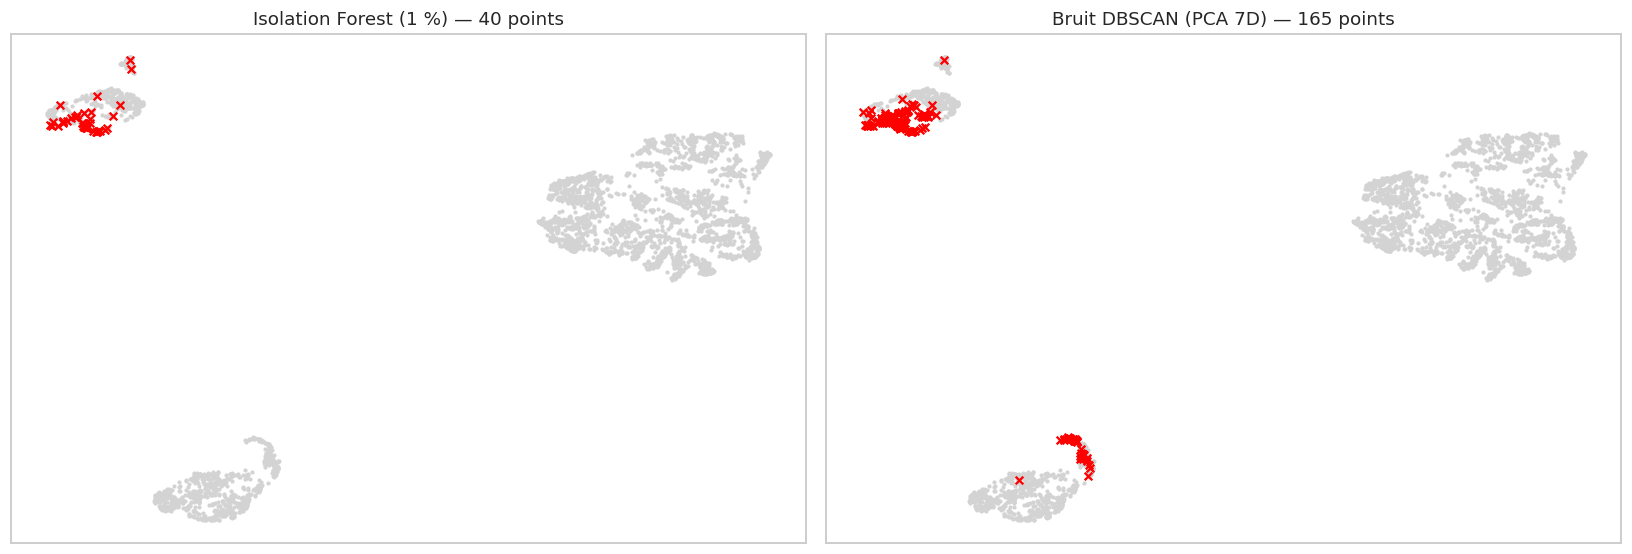

In [6]:
U = d["emb_umap2"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, m, t in [(axes[0], iso_s, "Isolation Forest (1 %)"), (axes[1], noise_pca, "Bruit DBSCAN (PCA 7D)")]:
    ax.scatter(U[:, 0], U[:, 1], s=3, c="lightgrey")
    ax.scatter(U[m, 0], U[m, 1], s=25, c="red", marker="x"); ax.set_title(f"{t} — {m.sum()} points")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); save(fig, "b1_anomalies_umap")

**Lecture.**
- Les 411 atypiques Isolation Forest (1 %) sont des clients au **long historique** (≈ 2 contacts antérieurs contre 0,15, 64 % d'anciens succès) et souvent **retraités ou étudiants** (47 % contre 6 %), plus âgés (51 ans). Leur taux de souscription atteint **54 %** (contre 11 %) : ce ne sont pas des erreurs mais des **niches à très forte valeur**, logées dans S3 (30 %) et S4 (70 %).
- Le bruit DBSCAN dans l'espace PCA a un score IF moyen (0,55) nettement supérieur à celui de l'échantillon (0,46) et recouvre 21 % des atypiques IF : les deux approches convergent partiellement. Le bruit UMAP en recouvre moins (9 %) : UMAP « rapproche » certains atypiques de leurs voisins et isole plutôt des points de frontière entre îlots.
- **Usage métier** : traiter ces clients hors segmentation (revue individuelle par un conseiller) et les exclure lors du ré-apprentissage des centroïdes pour éviter qu'ils ne les déplacent.

## Partie B — Sélection de caractéristiques avant clustering
Évaluation commune : K-means **k = 4** (n_init = 10) sur l'échantillon, indices internes **dans l'espace sélectionné**, V-mesure vs `y`, et dépendance à la période d'appel (V de Cramér entre segment et décile chronologique, plus il est faible moins la segmentation est « conjoncturelle »).

In [7]:
period = pd.cut(np.arange(len(clean)), 10, labels=False)[idx]
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
def evaluate(cols, name):
    Z = X[idx][:, cols]
    lab = KMeans(4, n_init=10, random_state=SEED).fit_predict(Z)
    return {"jeu": name, "n_colonnes": len(cols), "silhouette": silhouette_score(Z, lab),
            "davies_bouldin": davies_bouldin_score(Z, lab), "V_mesure_y": v_measure_score(y[idx], lab),
            "V_Cramer_periode": cramers_v(lab, period), "labels": lab}
all_cols = list(range(X.shape[1]))
results = [evaluate(all_cols, "Toutes les variables")]

### B.1 Filtre de variance
Les variables numériques sont standardisées (variance 1) : le filtre ne s'applique utilement qu'aux **colonnes binaires / one-hot**, dont la variance vaut $p(1-p)$. Un seuil de 0,03 supprime les modalités portées par moins de ~3 % des clients.

In [8]:
nb = len(NUM_FEATURES)
vt = VarianceThreshold(0.03).fit(X[:, nb:])
var_cols = list(range(nb)) + [nb + i for i in np.where(vt.get_support())[0]]
print("Colonnes supprimées :", {feat_names[i]: round(X[:, i].mean(), 3) for i in all_cols if i not in var_cols})
results.append(evaluate(var_cols, "Filtre variance"))

Colonnes supprimées : {'job_housemaid': np.float64(0.026), 'job_student': np.float64(0.021), 'job_unemployed': np.float64(0.025)}


### B.2 Filtre de redondance (corrélation)

In [9]:
C = pd.DataFrame(X, columns=feat_names).corr().abs()
upper = C.where(np.triu(np.ones(C.shape), 1).astype(bool))
pairs = upper.stack()[lambda s: s > 0.7].sort_values(ascending=False)
print("Paires |r| > 0,7 :\n", pairs.round(3))
drop = {b for (a, b) in pairs.index}
corr_cols = [i for i, f in enumerate(feat_names) if f not in drop]
print("Supprimées :", drop)
results.append(evaluate(corr_cols, "Filtre corrélation"))

Paires |r| > 0,7 :
 previous          poutcome_nonexistent    0.879
poutcome_failure  poutcome_nonexistent    0.853
marital_married   marital_single          0.777
dtype: float64
Supprimées : {'poutcome_nonexistent', 'marital_single'}


### B.3 Méthode *wrapper* : sélection avant pas à pas
On ajoute à chaque étape la **variable d'origine** (groupe de colonnes one-hot) qui maximise la silhouette de K-means (k = 4). On trace la silhouette en fonction du nombre de variables.

,variable ajoutée,silhouette
1,housing,1.000
2,loan,1.000
3,poutcome,0.783
4,previous,0.743
5,euribor3m,0.637
6,contact_cellular,0.561
7,campaign_log,0.383
8,default_flag,0.353
9,marital,0.287
10,cons.conf.idx,0.235


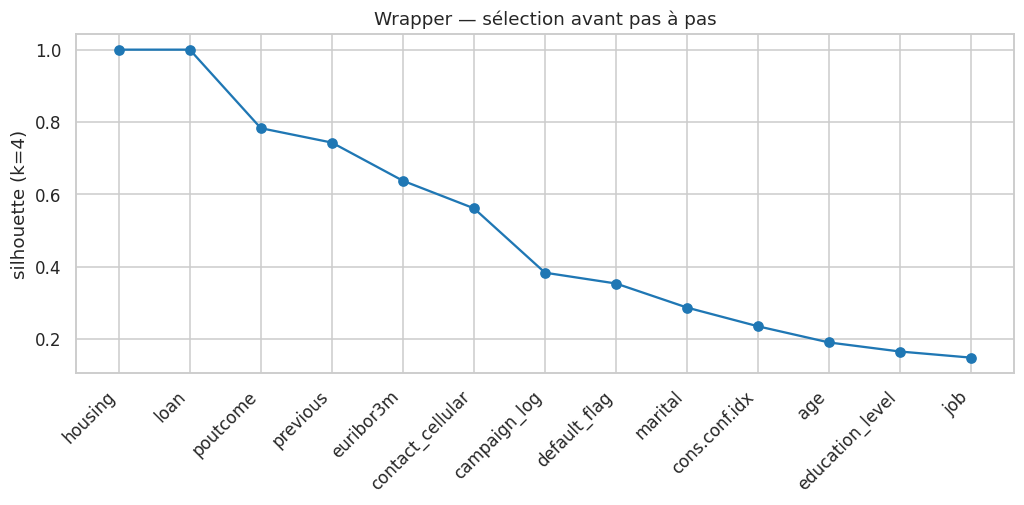

In [10]:
groups = {v: [i for i, f in enumerate(feat_names) if f == v or f.startswith(v + "_")]
          for v in NUM_FEATURES + BIN_FEATURES + CAT_FEATURES}
selected, remaining, path = [], list(groups), []
Xs_full = X[idx]
while remaining:
    best_v, best_s = None, -1
    for v in remaining:
        cols = sum((groups[g] for g in selected + [v]), [])
        lab = KMeans(4, n_init=3, random_state=SEED).fit_predict(Xs_full[:, cols])
        s = silhouette_score(Xs_full[:, cols], lab)
        if s > best_s: best_v, best_s = v, s
    selected.append(best_v); remaining.remove(best_v); path.append((best_v, best_s))
path_df = pd.DataFrame(path, columns=["variable ajoutée", "silhouette"]); path_df.index += 1
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(path_df.index, path_df["silhouette"], "o-")
ax.set_xticks(path_df.index); ax.set_xticklabels(path_df["variable ajoutée"], rotation=45, ha="right")
ax.set_ylabel("silhouette (k=4)"); ax.set_title("Wrapper — sélection avant pas à pas"); save(fig, "b2_wrapper")
path_df.round(3)

Biais connu du wrapper non supervisé : la silhouette favorise les **petits sous-espaces** où quelques variables discrètes créent des groupes triviaux. On impose donc une taille minimale de **6 variables** (diversité nécessaire pour un profil marketing) et on retient le sous-ensemble à 6 variables du chemin.

In [11]:
wrap_vars = path_df["variable ajoutée"].iloc[:6].tolist()
wrap_cols = sum((groups[g] for g in wrap_vars), [])
print("Variables wrapper :", wrap_vars)
results.append(evaluate(wrap_cols, "Wrapper (6 variables)"))

Variables wrapper : ['housing', 'loan', 'poutcome', 'previous', 'euribor3m', 'contact_cellular']


### B.4 Variante « profil client pur » (sans indicateurs macro-économiques)

In [12]:
pure_cols = [i for i, f in enumerate(feat_names) if f not in ("euribor3m", "cons.conf.idx")]
results.append(evaluate(pure_cols, "Profil pur (sans macro)"))

In [13]:
fs = pd.DataFrame([{k: v for k, v in r.items() if k != "labels"} for r in results]).set_index("jeu")
fs["ARI vs toutes variables"] = [adjusted_rand_score(results[0]["labels"], r["labels"]) for r in results]
fs.to_csv(RESULTS / "b2_selection_variables.csv")
fs.round(3)

,n_colonnes,silhouette,davies_bouldin,V_mesure_y,V_Cramer_periode,ARI vs toutes variables
jeu,,,,,,
Toutes les variables,27,0.148,1.948,0.024,0.541,1.000
Filtre variance,24,0.150,1.935,0.024,0.541,0.988
Filtre corrélation,25,0.149,1.948,0.024,0.542,0.914
Wrapper (6 variables),8,0.561,0.783,0.060,0.573,0.512
Profil pur (sans macro),25,0.156,1.780,0.015,0.307,0.450


**Synthèse de la sélection de variables**
- Le **filtre de variance** retire les modalités rares (petits métiers) : effet limité sur les indices, mais attention à ne pas perdre des niches utiles.
- Le **filtre de corrélation** supprime les redondances one-hot (`poutcome_nonexistent` ↔ `poutcome_failure`/`previous`) sans changer beaucoup la partition.
- Le **wrapper** illustre parfaitement son biais : `housing` + `loan` seuls donnent une silhouette de **1,0** (4 combinaisons oui/non = 4 « clusters » parfaits mais sans intérêt métier). Avec 6 variables la silhouette reste très élevée (0,56) mais le critère s'auto-justifie (on optimise ce que l'on mesure) : la sélection doit être validée par l'interprétabilité et le métier.
- La variante **profil pur** fait chuter la dépendance à la période (V de Cramér) : la segmentation devient plus « intrinsèque » au client, au prix d'un pouvoir discriminant sur `y` plus faible — preuve que le **contexte de taux** explique une grande partie de la souscription. Les deux visions sont complémentaires : profil pur pour le CRM, segmentation complète pour le pilotage des campagnes.